# 03 - Module 1: Customer segmentation

**Goal:** split the customers into a few groups that behave alike, using only how recently, how often and how
much they bought (**R**ecency, **F**requency, **M**onetary value). Then give each group a business name and add it
to both customer tables as a `segment` column, which Modules 2 and 3 use as a feature.

**This is unsupervised learning:** no target is used to build the groups. The churn and spend targets are
only looked at afterwards, to check whether the groups mean something.

**Leakage rule for this module:** the log transform, the scaler and the clustering are **fit on the train table
only**. The test table is only passed through `.predict()`.

**Steps**
1. Load the customer tables from notebook 02
2. Prepare R, F, M: `log1p` + `StandardScaler` (fit on train)
3. K-means for k = 2..10: choose k with the elbow, silhouette and Davies-Bouldin
4. Fit the final K-means, profile the clusters and name them
5. Hierarchical clustering (Ward) with a dendrogram, for comparison
6. Gaussian mixture model (GMM) with BIC, for comparison
7. Compare the three methods and choose one
8. Pictures: PCA and t-SNE (t-SNE for the picture only)
9. Segment profiles
10. Apply the segments to the test table
11. Save

In [1]:
import sys
sys.path.append("..")   # lets the notebook import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from matplotlib import patheffects
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture

from src import config, evaluation, segmentation

pd.set_option("display.max_columns", 50)
np.random.seed(config.RANDOM_STATE)

evaluation.set_plot_style()
BLUE = config.COLORS["segmentation"]   # the segmentation module colour
INK = config.COLORS["ink"]
SEG_COLORS = config.SEGMENT_COLORS     # one colour per segment, in display order
SEGMENTS = segmentation.SEGMENT_NAMES  # ["Champions", "Promising", "At-risk", "Lost / One-time"]
RFM = segmentation.RFM_COLUMNS         # ["recency_days", "frequency", "monetary"]

## 1. Load the customer tables

In [2]:
# This notebook adds a `segment` column and saves the tables again. Drop it here, so
# running the notebook a second time starts from exactly the same input.
train = pd.read_parquet(config.TRAIN_TABLE).drop(columns="segment", errors="ignore")
test = pd.read_parquet(config.TEST_TABLE).drop(columns="segment", errors="ignore")

print(f"train: {len(train):,} customers | test: {len(test):,} customers")
train[RFM].describe().round(1)

train: 4,908 customers | test: 5,224 customers


,recency_days,frequency,monetary
count,4908.0,4908.0,4908.0
mean,167.8,5.2,2363.2
std,141.4,9.9,10458.5
min,0.0,1.0,1.6
25%,43.0,1.0,311.4
50%,153.0,3.0,738.3
75%,242.0,6.0,1924.7
max,546.0,234.0,385971.8


## 2. Prepare R, F and M

K-means groups customers by **distance**, so two things matter:

1. **Skew.** Frequency and monetary are extremely right-skewed: the median customer spent about £740, the
   biggest wholesaler about £386,000. On the raw scale that one customer would sit far away from everyone else
   and dominate the distances. `log1p(x) = log(1 + x)` pulls the long tail in (and works for recency = 0).
2. **Units.** Days, orders and pounds have different scales. `StandardScaler` gives every column mean 0 and
   standard deviation 1, so each of R, F and M counts equally.

Both steps are learned from the **train** table and only applied to the test table.

In [3]:
prep = segmentation.make_preprocessor().fit(train[RFM])   # learns the means/stds from TRAIN only
X_train = prep.transform(train[RFM])
X_test = prep.transform(test[RFM])                        # test is only transformed, never fitted

pd.DataFrame({
    "skew (raw)": train[RFM].skew(),
    "skew (after log1p)": np.log1p(train[RFM]).skew(),
    "train mean (scaled)": X_train.mean(axis=0),
    "train std (scaled)": X_train.std(axis=0),
    "test mean (scaled)": X_test.mean(axis=0),
}).round(2)

,skew (raw),skew (after log1p),train mean (scaled),train std (scaled),test mean (scaled)
recency_days,0.79,-0.96,0.0,1.0,0.13
frequency,9.98,1.10,-0.0,1.0,0.06
monetary,23.35,0.26,-0.0,1.0,0.03


- After `log1p` the skew of frequency and monetary falls from about 10 and 23 to about 1 or less.
- The scaled train columns have mean 0 and standard deviation 1, as intended. The test means are slightly off
  0, because the test table comes from a different date, and that is expected. Refitting the scaler on test
  would hide this, and it would also be leakage.

In [4]:
# Correlation of the three scaled columns
pd.DataFrame(X_train, columns=RFM).corr().round(2)

,recency_days,frequency,monetary
recency_days,1.00,-0.55,-0.49
frequency,-0.55,1.00,0.84
monetary,-0.49,0.84,1.00


Frequency and monetary are strongly correlated (0.84): customers who order more also spend more in total.
So in practice the clustering sees two main directions: **how valuable** a customer is (F and M together) and
**how recently** they bought (R). The PCA in Section 8 confirms this.

## 3. K-means: how many clusters?

**K-means** places k centres and assigns every customer to the nearest one. It then moves each centre to the
mean of its customers, and repeats until nothing changes. We must choose k ourselves, so we try k = 2..10 and
compare three scores (all computed on the scaled train data):

| Score | Meaning | Better |
|---|---|---|
| inertia | total squared distance of customers to their centre | lower, but it *always* falls as k grows, so we look for the "elbow" |
| silhouette | how much closer a customer is to its own cluster than to the next one (-1 to 1) | higher |
| Davies-Bouldin | how similar each cluster is to its closest other cluster | lower |

In [5]:
k_scores = segmentation.compare_k(X_train, range(2, 11))
evaluation.save_table(k_scores, "segmentation_k_selection")
k_scores.round(3)

,k,inertia,silhouette,davies_bouldin,smallest_cluster
0,2,7228.287,0.456,0.865,1756
1,3,5456.893,0.351,1.031,868
2,4,4221.169,0.378,0.918,719
3,5,3559.298,0.330,0.958,491
4,6,3113.066,0.326,0.934,440
5,7,2821.489,0.289,0.982,356
6,8,2556.959,0.288,1.008,134
7,9,2345.276,0.290,1.003,127
8,10,2184.219,0.278,1.015,129


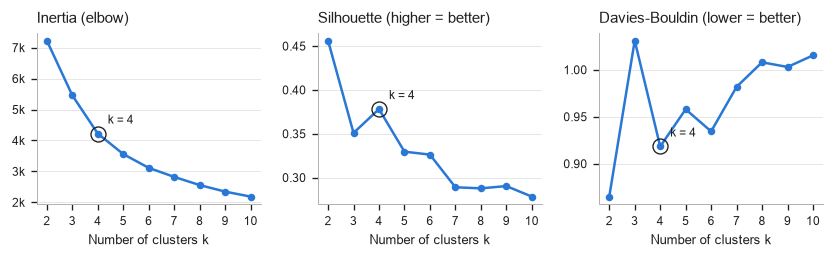

In [6]:
K = 4   # the chosen number of clusters (reasons below)

fig, axes = plt.subplots(1, 3, figsize=(7, 2.2))
panels = [("inertia", "Inertia (elbow)"),
          ("silhouette", "Silhouette (higher = better)"),
          ("davies_bouldin", "Davies-Bouldin (lower = better)")]
for ax, (column, title) in zip(axes, panels):
    ax.plot(k_scores["k"], k_scores[column], color=BLUE, marker="o", markersize=3.5, linewidth=1.5)
    chosen = k_scores.loc[k_scores["k"] == K, column].iloc[0]
    # a ring around the chosen k
    ax.plot(K, chosen, marker="o", markersize=9, markerfacecolor="none", markeredgecolor=INK, markeredgewidth=0.8)
    ax.annotate(f"k = {K}", (K, chosen), xytext=(6, 6), textcoords="offset points", fontsize=7)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Number of clusters k")
    ax.set_xticks(k_scores["k"])
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
fig.tight_layout()
evaluation.save_fig(fig, "seg_choose_k")
plt.show()

**We choose k = 4.**
- **k = 2 has the best silhouette (0.46), but it only splits "active" from "inactive" customers.** That is too
  coarse to act on, so we look for the best k from 3 upwards.
- **From k = 3 upwards, k = 4 has the highest silhouette (0.38) and the lowest Davies-Bouldin (0.92).**
  The two scores agree.
- **The elbow is around k = 4.** After that, every extra cluster lowers the inertia less and less.
- **It matches the 3-5 segments that RFM studies usually report** and is small enough to explain to a
  marketing team.

**Is the result stable?** K-means starts from random centres, so we refit it from 5 different random seeds and
compare the groupings with the **Adjusted Rand Index (ARI)**. ARI is 1 when two groupings put exactly the
same customers together (the cluster numbers themselves do not matter) and about 0 for random groupings.

In [7]:
# The seed is changed on purpose here (0..4): this cell only checks stability.
labels_by_seed = [KMeans(n_clusters=K, n_init=10, random_state=seed).fit_predict(X_train) for seed in range(5)]
ari_vs_first = [adjusted_rand_score(labels_by_seed[0], other) for other in labels_by_seed[1:]]
print("ARI of seeds 1-4 against seed 0:", np.round(ari_vs_first, 3))

ARI of seeds 1-4 against seed 0: [0.996 0.994 0.996 0.992]


The ARI is about 0.99 or higher for every seed, so the 4 clusters are a real structure in the data, not an
accident of the starting point.

## 4. Fit the final K-means and name the clusters

The final model is one sklearn `Pipeline`: `log1p`, then `StandardScaler`, then `KMeans(k=4)`. It is fit
on the train table. For any table, `model.predict(table[RFM])` then applies the same three steps with the
values learned from train.

In [8]:
kmeans_model = segmentation.make_kmeans_pipeline(K).fit(train[RFM])   # fit on TRAIN only
train_clusters = kmeans_model.predict(train[RFM])

profile = segmentation.profile_segments(train, train_clusters)
profile.round(2)

,customers,share,recency_mean,recency_median,frequency_mean,frequency_median,monetary_mean,monetary_median,churn_rate,mean_next_spend,revenue_share
cluster,,,,,,,,,,,
0,1992,0.41,269.83,238.0,1.37,1.0,326.43,289.01,0.89,36.82,0.06
1,719,0.15,25.68,22.0,3.05,3.0,882.57,721.96,0.56,194.37,0.05
2,1435,0.29,172.25,174.0,4.81,4.0,1900.44,1386.12,0.67,196.95,0.24
3,762,0.16,26.90,19.0,18.03,13.0,9955.90,4954.66,0.21,1526.24,0.65


The cluster numbers 0-3 are arbitrary (another sklearn version could number them differently). So
`name_clusters()` names them with rules on the median R, F and M, not by hand:
- the highest median spend → **Champions**
- the longest time since the last purchase → **Lost / One-time**
- of the remaining two, the more recent → **Promising**, the other → **At-risk**

In [9]:
names = segmentation.name_clusters(profile)
print("cluster number -> name:", names)

profile_named = profile.rename(index=names).loc[SEGMENTS]
profile_named.index.name = "segment"
evaluation.save_table(profile_named.reset_index(), "segment_profiles_train")
profile_named.round(2)

cluster number -> name: {3: 'Champions', 1: 'Promising', 2: 'At-risk', 0: 'Lost / One-time'}


,customers,share,recency_mean,recency_median,frequency_mean,frequency_median,monetary_mean,monetary_median,churn_rate,mean_next_spend,revenue_share
segment,,,,,,,,,,,
Champions,762,0.16,26.90,19.0,18.03,13.0,9955.90,4954.66,0.21,1526.24,0.65
Promising,719,0.15,25.68,22.0,3.05,3.0,882.57,721.96,0.56,194.37,0.05
At-risk,1435,0.29,172.25,174.0,4.81,4.0,1900.44,1386.12,0.67,196.95,0.24
Lost / One-time,1992,0.41,269.83,238.0,1.37,1.0,326.43,289.01,0.89,36.82,0.06


**What the four segments look like (train table, cutoff 1 June 2011):**

| Segment | Who they are | Suggested action |
|---|---|---|
| **Champions** (~16%) | bought in the last few weeks, order often (median 13 orders), spent the most (median about £5,000). They brought in 65% of all past revenue. | keep them happy: loyalty rewards, early access |
| **Promising** (~15%) | also bought recently, but only a few orders so far (median 3) and small totals | help them buy again: welcome or second-order offers |
| **At-risk** (~29%) | used to buy several times (median 4 orders, about £1,400), but nothing for about 6 months | win them back before they are lost |
| **Lost / One-time** (~41%) | last order about 8 months ago, and most ordered only once | cheap mass campaigns at most |

**Check against the targets (not used for the clustering):** the churn rate climbs steadily from Champions (21%)
to Promising (56%), At-risk (67%) and Lost (89%), and the Champions spend by far the most in the next 90 days.
So the segments carry real information about the future. That is why they are useful as a feature in
Modules 2 and 3.

## 5. Hierarchical clustering (Ward), for comparison

**Agglomerative (bottom-up) clustering** starts with every customer as its own cluster. It then keeps merging the
two closest clusters until only one is left. **Ward linkage** defines "closest" as the merge that increases the
within-cluster variance the least. This is the same quantity K-means minimises. The **dendrogram** is the tree of
merges, and the height of a merge shows how different the two joined groups were. With about 4,900 customers this
takes about 2 seconds, so no subsample is needed.

In [10]:
Z = linkage(X_train, method="ward")   # the full merge tree (rows = merges, column 2 = merge height)

# Height of the last merges: a big jump means two very different groups were forced together.
last_merges = pd.Series(Z[-6:, 2][::-1], index=[f"{n + 1} -> {n} clusters" for n in range(1, 7)])
last_merges.round(1)

2 -> 1 clusters    111.4
3 -> 2 clusters     73.8
4 -> 3 clusters     45.4
5 -> 4 clusters     38.2
6 -> 5 clusters     36.1
7 -> 6 clusters     24.8
dtype: float64

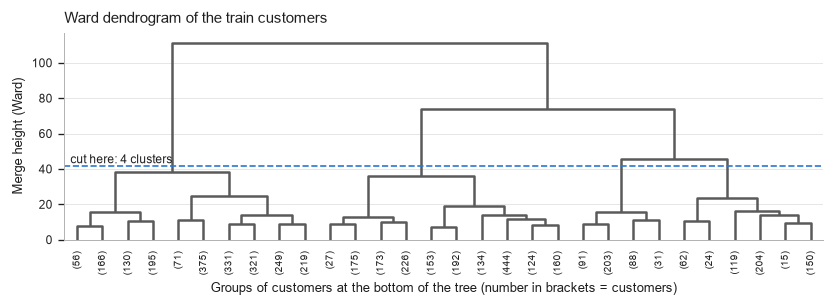

In [11]:
# Cut the tree between the merges "5 -> 4" (Z[-4]) and "4 -> 3" (Z[-3]): this leaves 4 clusters.
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2

fig, ax = plt.subplots(figsize=(7, 2.6))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax,          # show only the last 30 merged groups
           link_color_func=lambda _: "#5a5a5a", leaf_font_size=6, leaf_rotation=90)
ax.axhline(cut_height, color=BLUE, linestyle="--", linewidth=1)
ax.text(ax.get_xlim()[0], cut_height, f"  cut here: {K} clusters", ha="left", va="bottom", fontsize=7)
ax.set_ylabel("Merge height (Ward)")
ax.set_xlabel("Groups of customers at the bottom of the tree (number in brackets = customers)")
ax.set_title("Ward dendrogram of the train customers", loc="left")
fig.tight_layout()
evaluation.save_fig(fig, "seg_dendrogram")
plt.show()

In [12]:
ward_labels = fcluster(Z, t=K, criterion="maxclust")   # cluster number 1..4 for every customer
train_segment = pd.Series(train_clusters).map(names)   # the K-means segment name of every customer

pd.crosstab(train_segment, ward_labels, rownames=["K-means segment"], colnames=["Ward cluster"]).loc[SEGMENTS]

Ward cluster,1,2,3,4
K-means segment,,,,
Champions,0,128,64,570
Promising,230,138,347,4
At-risk,27,1406,2,0
Lost / One-time,1856,136,0,0


- **The dendrogram shows large jumps for the last merges** (into 3, 2 and 1 clusters), so 2-4 groups are
  natural. A cut at 4 is consistent with the K-means choice.
- **The crosstab shows that Ward finds similar groups.** Champions, At-risk and Lost / One-time each fall
  mostly into one Ward cluster. The Promising segment is split over three Ward clusters, so that is where the two
  methods draw different borders. The agreement is measured in Section 7.
- **Ward has no `predict()`.** A new customer (for example in the test table) cannot be placed into the
  tree, so it cannot give segments for the test table without extra work.

## 6. Gaussian mixture model (GMM), for comparison

A **GMM** assumes the data is a mix of k "bell-shaped" (Gaussian) groups. Each group can be stretched and
tilted (an ellipse, not a ball as in K-means), and every customer gets a *probability* of belonging to each
group. We choose the number of components with **BIC** (lower = better): it rewards a good fit but charges a
penalty for every extra parameter.

In [13]:
bic = segmentation.gmm_bic(X_train, range(2, 11))
bic.round(0)

,n_components,bic
0,2,31439.0
1,3,14751.0
2,4,14507.0
3,5,14274.0
4,6,6003.0
5,7,906.0
6,8,840.0
7,9,894.0
8,10,-7002.0


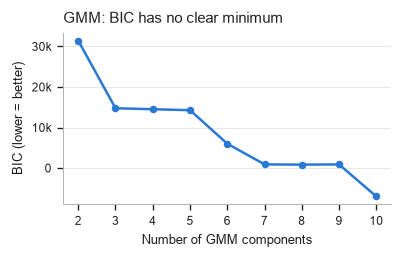

In [14]:
fig, ax = plt.subplots(figsize=(3.4, 2.2))
ax.plot(bic["n_components"], bic["bic"], color=BLUE, marker="o", markersize=3.5, linewidth=1.5)
ax.set_xticks(bic["n_components"])
ax.set_xlabel("Number of GMM components")
ax.set_ylabel("BIC (lower = better)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "0" if v == 0 else f"{v / 1000:.0f}k"))
ax.set_title("GMM: BIC has no clear minimum", loc="left")
fig.tight_layout()
evaluation.save_fig(fig, "seg_gmm_bic")
plt.show()

**BIC has no clear minimum.** It falls in big steps (at 3, 6, 7 and 10 components) and is lowest at the largest
number we tried. If we followed it, we would get more and more components, which is useless for segments. The
reason shows up in the components of a 4-component GMM:

In [15]:
gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=3,
                      random_state=config.RANDOM_STATE).fit(X_train)
gmm_labels = gmm.predict(X_train)

pd.DataFrame({
    "customers": np.bincount(gmm_labels, minlength=K),
    "distinct frequency values": [train.loc[gmm_labels == c, "frequency"].nunique() for c in range(K)],
    # variance along the flattest direction of the component's ellipse
    "smallest variance": [np.linalg.eigvalsh(cov).min() for cov in gmm.covariances_],
}).rename_axis("GMM component")

,customers,distinct frequency values,smallest variance
GMM component,,,
0,1541,1,1.000000e-06
1,883,8,7.194444e-02
2,1154,71,1.690436e-01
3,1330,5,5.890563e-02


- **One component holds only one-order customers** (a single distinct frequency value), and its smallest variance
  is 0.000001. That is the minimum sklearn allows (`reg_covar`). About 31% of customers have frequency = 1, and
  after `log1p` and scaling they all share **exactly the same value**. A Gaussian can be squeezed flat onto that
  value, which makes its likelihood huge.
- **With more components, the same thing happens for frequency = 2, 3, ...** Each new flat component raises the
  likelihood more than BIC's penalty, which explains the big downward steps.
- **So BIC cannot choose k here.** For a fair comparison with K-means we use the GMM with the same k = 4.

## 7. Compare the three methods

In [16]:
def method_scores(method, labels, assigns_new_customers):
    # all scores on the same scaled train data; ARI = agreement with the K-means grouping
    return {
        "method": method,
        "clusters": len(np.unique(labels)),
        "silhouette": silhouette_score(X_train, labels),
        "davies_bouldin": davies_bouldin_score(X_train, labels),
        "ARI_vs_kmeans": adjusted_rand_score(train_clusters, labels),
        "assigns_new_customers": assigns_new_customers,
    }


comparison = pd.DataFrame([
    method_scores("K-means", train_clusters, "yes (predict)"),
    method_scores("Hierarchical (Ward)", ward_labels, "no"),
    method_scores("Gaussian mixture", gmm_labels, "yes (predict)"),
])
evaluation.save_table(comparison, "segmentation_method_comparison")
comparison.round(3)

,method,clusters,silhouette,davies_bouldin,ARI_vs_kmeans,assigns_new_customers
0,K-means,4,0.378,0.918,1.000,yes (predict)
1,Hierarchical (Ward),4,0.333,0.953,0.676,no
2,Gaussian mixture,4,0.245,1.200,0.422,yes (predict)


**We keep K-means (k = 4)** for the final segments:
- **Best scores.** It has the highest silhouette and the lowest Davies-Bouldin of the three.
- **It assigns new customers.** `predict()` places test customers into the segments learned on train. Ward
  cannot do this.
- **Easy to explain.** The segments are clear groups in R, F and M with obvious business names.

**The alternatives:**
- **Ward** agrees fairly well with K-means: both minimise within-cluster variance.
- **The GMM** splits the customers differently. Part of it is spent on the flat one-order component, which
  follows the shape of the data rather than a business difference between customers.

## 8. Pictures of the segments: PCA and t-SNE

Our data has 3 dimensions (R, F, M), so we project it to 2 dimensions to draw it. Both methods are fit on the
scaled train data and only used for pictures:
- **PCA** finds the directions with the most variance. The axes have a meaning, and distances are kept as
  well as possible.
- **t-SNE** places customers so that close neighbours stay close. It is good at showing groups, but it distorts
  distances and cluster sizes, so the axes have no meaning. **It is never used as input for the clustering.**

In [17]:
pca = PCA(n_components=3, random_state=config.RANDOM_STATE).fit(X_train)
pca_2d = pca.transform(X_train)[:, :2]

pd.DataFrame(pca.components_, columns=RFM, index=["PC1", "PC2", "PC3"]).assign(
    explained_variance=pca.explained_variance_ratio_).round(3)

,recency_days,frequency,monetary,explained_variance
PC1,-0.503,0.619,0.603,0.755
PC2,0.859,0.282,0.427,0.192
PC3,0.095,0.733,-0.674,0.053


- **PC1 explains about 75% of the variance:** low recency, high frequency and high monetary all point the same
  way, so PC1 is an **overall customer value** axis.
- **PC2 adds about 19% and is mostly recency.**
- **Together the two axes keep about 95% of the information**, so the 2D picture is faithful.

In [18]:
# t-SNE for the PICTURE only (about a minute). perplexity ~ the number of neighbours each point "looks at".
tsne_2d = TSNE(n_components=2, perplexity=30, init="pca", random_state=config.RANDOM_STATE).fit_transform(X_train)

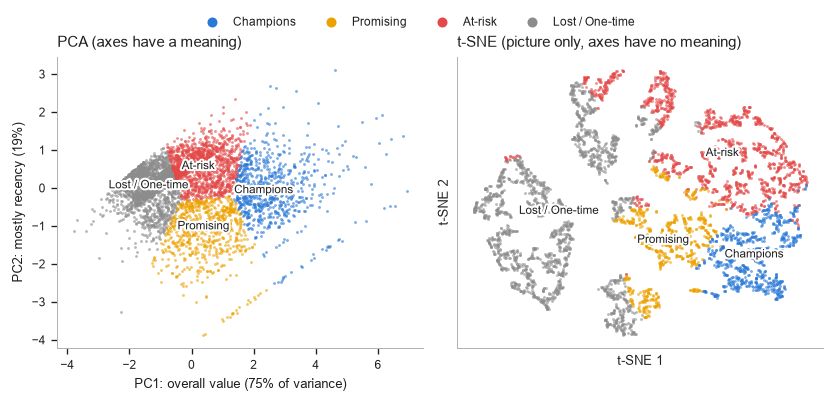

In [19]:
segment_of_customer = train_segment.to_numpy()
halo = [patheffects.withStroke(linewidth=2.5, foreground="white")]   # white outline so labels stay readable


def scatter_segments(ax, xy, title):
    # Draw the big grey "Lost" group first, so the smaller groups are drawn on top of it.
    for name in reversed(SEGMENTS):
        points = xy[segment_of_customer == name]
        ax.scatter(points[:, 0], points[:, 1], s=3, color=SEG_COLORS[name], alpha=0.6,
                   linewidths=0, rasterized=True)
    # Name each group at its middle (median point).
    for name in SEGMENTS:
        mid_x, mid_y = np.median(xy[segment_of_customer == name], axis=0)
        ax.text(mid_x, mid_y, name, ha="center", va="center", fontsize=7, color=INK, path_effects=halo)
    ax.set_title(title, loc="left")
    ax.grid(False)


fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
scatter_segments(axes[0], pca_2d, "PCA (axes have a meaning)")
axes[0].set_xlabel(f"PC1: overall value ({pca.explained_variance_ratio_[0]:.0%} of variance)")
axes[0].set_ylabel(f"PC2: mostly recency ({pca.explained_variance_ratio_[1]:.0%})")
scatter_segments(axes[1], tsne_2d, "t-SNE (picture only, axes have no meaning)")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

legend_handles = [Line2D([], [], marker="o", linestyle="", markersize=5, color=SEG_COLORS[n], label=n)
                  for n in SEGMENTS]
fig.legend(handles=legend_handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
evaluation.save_fig(fig, "seg_pca_tsne")
plt.show()

- **PCA:** the segments lie side by side along PC1 (value): Lost, then At-risk and Promising, then Champions.
  Promising and At-risk are separated by PC2 (recency): both are mid-value, but Promising bought recently.
- **t-SNE:** the colours stay together in regions, so the four segments are also groups of close neighbours.
  But t-SNE also breaks Lost / One-time and At-risk into several separate islands. t-SNE exaggerates small gaps,
  so islands in a t-SNE plot do not prove that there are separate groups. This is one more reason it is used
  for pictures only.
- **In the PCA plot the groups touch, with no empty gaps between them.** Customer behaviour is a continuum, and
  the segments are a useful way to cut it, not natural "species". This is also why the silhouette (0.38) is
  moderate rather than high.

## 9. Segment profiles

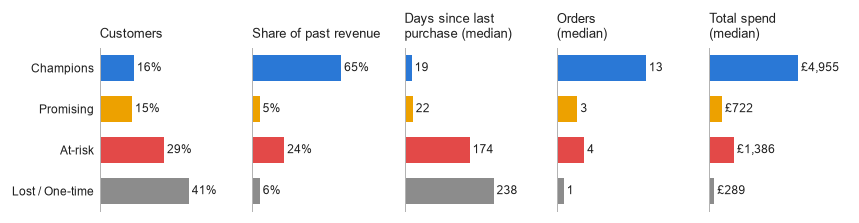

In [20]:
def pct(v):
    return f"{v:.0%}"


def whole(v):
    return f"{v:.0f}"


def pounds(v):
    return f"£{v:,.0f}"


panels = [("share", "Customers", pct),
          ("revenue_share", "Share of past revenue", pct),
          ("recency_median", "Days since last\npurchase (median)", whole),
          ("frequency_median", "Orders\n(median)", whole),
          ("monetary_median", "Total spend\n(median)", pounds)]

fig, axes = plt.subplots(1, len(panels), figsize=(7.2, 1.9), sharey=True)
rows = np.arange(len(SEGMENTS))
for ax, (column, title, fmt) in zip(axes, panels):
    values = profile_named[column]
    ax.barh(rows, values, height=0.62, color=[SEG_COLORS[n] for n in SEGMENTS])
    for row, value in zip(rows, values):
        ax.text(value, row, " " + fmt(value), va="center", fontsize=7)   # the value at the end of the bar
    ax.set_title(title, loc="left", fontsize=8)
    ax.set_xlim(0, values.max() * 1.55)
    ax.set_xticks([])                    # the values are written on the bars instead
    ax.tick_params(axis="y", length=0)   # no tick dashes next to the bars
    ax.spines["bottom"].set_visible(False)
    ax.grid(False)
axes[0].set_yticks(rows, SEGMENTS)
axes[0].invert_yaxis()                   # Champions at the top
fig.tight_layout()
evaluation.save_fig(fig, "seg_profiles")
plt.show()

**The Champions are 16% of the customers but brought in 65% of the past revenue.** The Lost / One-time group is
the largest (41% of customers), but it brought in only 6%. This is the classic "few customers make most of the
money" pattern, and it is the main reason to treat the segments differently.

## 10. Apply the segments to the test table

The test customers go through the **same fitted pipeline** (train's log/scale values and train's centres), using
`predict` only. Each test customer's R, F, M are measured at the test cutoff, so a customer can be in a different
segment in the two tables.

In [21]:
train_seg = segmentation.add_segment(train, kmeans_model, names)
test_seg = segmentation.add_segment(test, kmeans_model, names)   # predict only, no refitting

train_vs_test = pd.DataFrame({
    "train_customers": train_seg["segment"].value_counts(),
    "train_share": train_seg["segment"].value_counts(normalize=True),
    "test_customers": test_seg["segment"].value_counts(),
    "test_share": test_seg["segment"].value_counts(normalize=True),
    "train_churn_rate": train_seg.groupby("segment")["churned"].mean(),
    "test_churn_rate": test_seg.groupby("segment")["churned"].mean(),
    "train_mean_next_spend": train_seg.groupby("segment")["next_period_spend"].mean(),
    "test_mean_next_spend": test_seg.groupby("segment")["next_period_spend"].mean(),
}).loc[SEGMENTS]
train_vs_test.index.name = "segment"
evaluation.save_table(train_vs_test.reset_index(), "segments_train_vs_test")
train_vs_test.round(3)

,train_customers,train_share,test_customers,test_share,train_churn_rate,test_churn_rate,train_mean_next_spend,test_mean_next_spend
segment,,,,,,,,
Champions,762,0.155,845,0.162,0.213,0.157,1526.245,2091.127
Promising,719,0.146,628,0.120,0.556,0.454,194.366,376.800
At-risk,1435,0.292,1625,0.311,0.669,0.538,196.951,318.407
Lost / One-time,1992,0.406,2126,0.407,0.888,0.798,36.823,79.688


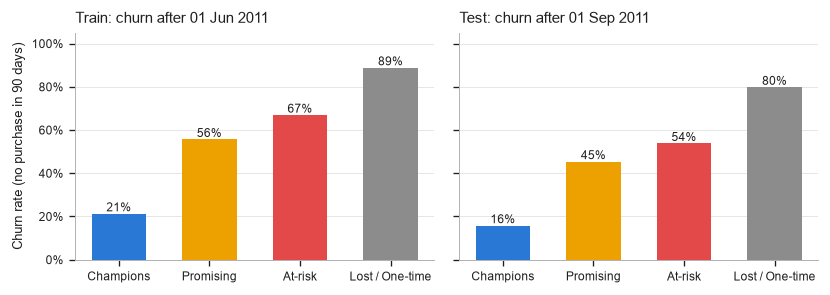

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.5), sharey=True)
tables = [(f"Train: churn after {config.TRAIN_CUTOFF:%d %b %Y}", train_seg),
          (f"Test: churn after {config.TEST_CUTOFF:%d %b %Y}", test_seg)]
for ax, (title, table) in zip(axes, tables):
    rates = table.groupby("segment")["churned"].mean().loc[SEGMENTS]
    ax.bar(range(len(SEGMENTS)), rates.values, width=0.6, color=[SEG_COLORS[n] for n in SEGMENTS])
    for x, rate in enumerate(rates.values):
        ax.text(x, rate, f"{rate:.0%}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(range(len(SEGMENTS)), SEGMENTS)
    ax.set_title(title, loc="left")
axes[0].set_ylabel("Churn rate (no purchase in 90 days)")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylim(0, 1.05)
fig.tight_layout()
evaluation.save_fig(fig, "seg_churn_by_segment")
plt.show()

- **The segment sizes are very similar in both tables** (Promising is a bit smaller on test: 12% vs 15%). The
  learned segments still describe the customer base three months later.
- **The churn order is identical on test:** Champions < Promising < At-risk < Lost.
- **Every segment churns less on test.** This is the seasonal shift from notebook 02: the test window is the
  autumn peak.

**Stability check (diagnostic only).** If we fit a fresh K-means on the test table, does it find the same
groups as the train model's `predict`? This new model is **thrown away**. It does not change any segment, so it
is not leakage. It only tells us whether the segment structure is stable over time.

In [23]:
refit_on_test = segmentation.make_kmeans_pipeline(K).fit(test[RFM])   # check only, not saved or used
ari_over_time = adjusted_rand_score(kmeans_model.predict(test[RFM]), refit_on_test.predict(test[RFM]))
print(f"ARI between train-model segments and a fresh test-only K-means: {ari_over_time:.3f}")

ARI between train-model segments and a fresh test-only K-means: 0.920


**How do customers move between segments?** Every train customer is also in the test table: the test population
is everyone who bought before 1 September, which includes everyone who bought before 1 June. (The other 316 test
customers made their first purchase between the two cutoffs.) So these customers were segmented twice, once at
each cutoff, three months apart. Each row below sums to 100%.

In [24]:
moves = train_seg[["customer_id", "segment"]].merge(
    test_seg[["customer_id", "segment"]], on="customer_id", suffixes=("_at_train_cutoff", "_at_test_cutoff"))

transitions = pd.crosstab(moves["segment_at_train_cutoff"], moves["segment_at_test_cutoff"],
                          normalize="index").loc[SEGMENTS, SEGMENTS]
evaluation.save_table(transitions.reset_index(), "segment_transitions")
print(f"{len(moves):,} customers are in both tables")
transitions.round(2)

4,908 customers are in both tables


segment_at_test_cutoff,Champions,Promising,At-risk,Lost / One-time
segment_at_train_cutoff,,,,
Champions,0.82,0.00,0.18,0.00
Promising,0.06,0.22,0.46,0.26
At-risk,0.12,0.06,0.78,0.04
Lost / One-time,0.00,0.08,0.02,0.90


- **Read along a row:** for example, the Champions row shows where the June Champions were in September.
- **A customer who buys nothing for three months can only "age".** Their recency grows by about 92 days, so they
  move to the right (towards At-risk and Lost).
- **Moving to the left needs new purchases.** For example, 12% of the At-risk customers bought again and became
  Champions.
- **Champions are the most stable:** 82% are still Champions three months later.
- **Promising is the least stable:** only 22% are still Promising. 46% have become At-risk and 26% Lost /
  One-time, which makes them the obvious target for a "second order" campaign.

## 11. Save

- Both customer tables get the `segment` column and are saved again. Notebooks 04 and 05 one-hot encode it.
- The fitted pipeline and the cluster names are saved together, so the same segments can be assigned later.

In [25]:
assert train_seg["segment"].notna().all() and test_seg["segment"].notna().all()
assert set(train_seg["segment"]) == set(SEGMENTS) and set(test_seg["segment"]) == set(SEGMENTS)

train_seg.to_parquet(config.TRAIN_TABLE, index=False)
test_seg.to_parquet(config.TEST_TABLE, index=False)
joblib.dump({"model": kmeans_model, "names": names}, config.SEGMENT_MODEL)

print(f"saved {len(train_seg):,} customers -> {config.TRAIN_TABLE.name} (now {train_seg.shape[1]} columns)")
print(f"saved {len(test_seg):,} customers -> {config.TEST_TABLE.name}")
print(f"saved the model -> models/{config.SEGMENT_MODEL.name}")

saved 4,908 customers -> customer_table_train.parquet (now 17 columns)
saved 5,224 customers -> customer_table_test.parquet
saved the model -> models/segmentation_kmeans.joblib


## 12. What we learned

- **Final model: K-means with k = 4 on log1p + standardised R, F, M**, fit on the train table only.
  - From k = 3 upwards, k = 4 has the best silhouette (0.38) and Davies-Bouldin (0.92).
  - It finds the same groups from every random start (ARI ≈ 0.99).
- **Four segments:**
  - **Champions** (16% of customers, 65% of past revenue, 21% churn)
  - **Promising** (15%, recent but few orders, 56% churn)
  - **At-risk** (29%, used to buy, 67% churn)
  - **Lost / One-time** (41%, 89% churn)
- **Comparisons:**
  - **Ward** finds similar groups (ARI about 0.68 with K-means) but cannot assign new customers.
  - **GMM's BIC keeps falling**, because components collapse onto the identical values of one-order customers,
    so BIC has no clear minimum and cannot choose k. At k = 4 the GMM separates the customers worst
    (silhouette 0.25).
- **Pictures:** PCA keeps about 95% of the variance in 2D (PC1 = overall value, PC2 = recency). t-SNE is used
  for the picture only.
- **Over time:**
  - On test the segments have similar sizes and the same churn order, and a test-only refit finds nearly the
    same groups (ARI 0.92).
  - Every segment churns less on test (seasonal shift).
  - Champions are the most stable segment (82% stay), Promising the least (22% stay).
- **Output:** a `segment` column in both customer tables (for Modules 2 and 3) and
  `models/segmentation_kmeans.joblib`.